# Thermal enclosure and a slow sensor

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/01-thermal-enclosure/notebook.ipynb)

## Goal
A camera enclosure receives a $40\,\mathrm{W}$ heat increment. Use thermal capacitance $C_{\mathrm{th}}=900\,\mathrm{J/K}$, conductance $H=15\,\mathrm{W/K}$ and sensor time constant $\tau_s=12\,\mathrm{s}$. Starting at ambient temperature, derive physical rise $x=T-T_a$ and sensor indication $y$, their poles and final values, and the sensor error after one enclosure time constant.

**Evidence:** every parameter and dataset is synthetic and was chosen for this original teaching scenario.

## Start from the physical system

![Physical system](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/01-thermal-enclosure/figures/physical-system.png)

Cutaway of a lumped thermal enclosure. Orange arrows carry heat; the probe measures a lagged temperature. The drawing fixes the energy boundary, not a real device geometry.

[Five integrated practice problems](https://github.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/01-thermal-enclosure/exercises.pdf) accompany this model.

The equipment view includes state and unit labels, governing balances and interpretation limits. [Vector PDF](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/01-thermal-enclosure/figures/physical-system.pdf) · [Editable TikZ](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/01-thermal-enclosure/figures/physical-system.tikz).


## Read the system diagram

![System diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/01-thermal-enclosure/figures/system-diagram.png)

Thermal storage, heat leakage and sensor dynamics are separate elements. The lower loop implements the energy balance, not an added temperature controller.

The diagram is original TikZ artwork; the numerical records below are synthetic.

## Setup
Run the optional installation cell if packages are missing. No private data, supplied PDFs or external model files are required.

In [ ]:
%pip -q install numpy scipy matplotlib control

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares
plt.ioff()
plt.rcParams.update({'figure.figsize': (9,4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})


## Derive the model
### Energy balance
Let $x=T-T_a$ denote temperature rise in kelvin and $P$ the incremental heat input in watts. With constant ambient temperature and a spatially uniform enclosure,

$$
C_{th}\dot x=P-Hx,\qquad \tau_s\dot y=x-y.
$$

The enclosure time constant is $\tau=C_{th}/H=60$ s and its static gain is $1/H=1/15$ K/W. The sensor does not change the enclosure energy balance.
### Cascade model
Taking Laplace transforms with zero initial deviations gives

$$
G_x(s)=\frac{1/15}{60s+1},\qquad G_y(s)=\frac{1/15}{(60s+1)(12s+1)}.
$$

The physical and measured responses share the final rise $40/15=8/3$ K, but the measured path adds the pole $-1/12$ to the thermal pole $-1/60$.
### Closed-form step responses
Integrating the energy balance gives $x(t)=\frac83(1-e^{-t/60})$. Partial fractions of $G_y(s)40/s$ give

$$
y(t)=\frac83\left[1-\frac{60e^{-t/60}-12e^{-t/12}}{48}\right].
$$

Both start at zero; $\dot x(0)=40/900$ K/s while $\dot y(0)=0$. Evaluate these expressions at $t=60$ s rather than treating 63.2 percent of the measured final value as the enclosure time constant.
### Model boundaries
Heat leakage is linearized and the enclosure is assumed well mixed. Radiation, internal temperature gradients, sensor self-heating and changing ambient temperature are omitted. Every curve is a simulation with invented design parameters.

## Compute and check
The first lines declare the scenario parameters. Follow the model construction, run the numerical experiment, and inspect the assertions and printed metrics.

In [2]:
capacity, conductance, sensor_tau, power = 900., 15., 12., 40.
tau = capacity / conductance
time = np.linspace(0, 420, 4201)
temperature = power/conductance*(1-np.exp(-time/tau))
indication = power/conductance*(1-(tau*np.exp(-time/tau)-sensor_tau*np.exp(-time/sensor_tau))/(tau-sensor_tau))
measured_model = ct.tf([1/conductance], np.convolve([tau,1],[sensor_tau,1]))
_, simulated = ct.step_response(power*measured_model, time)
assert np.max(np.abs(simulated-indication)) < 1e-9
error_at_tau = np.interp(tau,time,temperature-indication)
print(f'Thermal time constant: {tau:.3f} s; final rise: {power/conductance:.6f} K')
print(f'Sensor under-reading at 60 s: {error_at_tau:.6f} K')
assert error_at_tau > 0


Thermal time constant: 60.000 s; final rise: 2.666667 K
Sensor under-reading at 60 s: 0.240761 K


## Plot the evidence
The figure below displays the computed experiment. Axis units and legends distinguish the model variants; the curves are simulations.

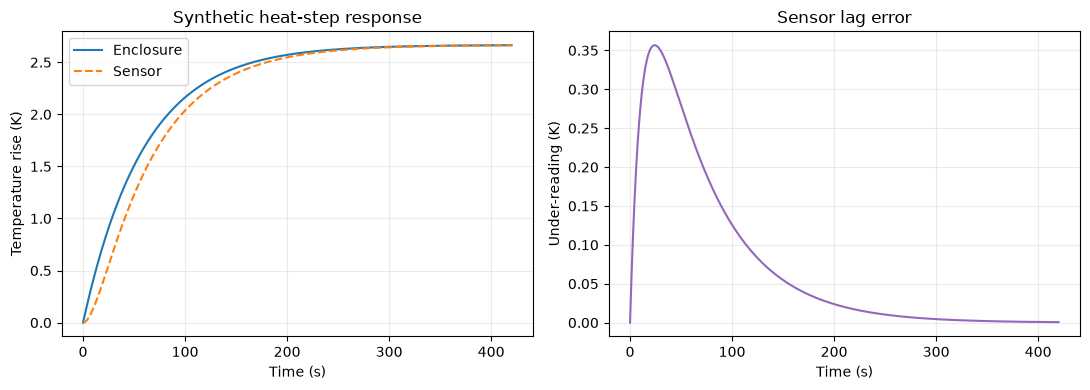

In [3]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(time,temperature,label='Enclosure'); axes[0].plot(time,indication,'--',label='Sensor')
axes[0].set(xlabel='Time (s)',ylabel='Temperature rise (K)',title='Synthetic heat-step response'); axes[0].legend()
axes[1].plot(time,temperature-indication,color='tab:purple')
axes[1].set(xlabel='Time (s)',ylabel='Under-reading (K)',title='Sensor lag error')
fig.tight_layout()

plt.show()

## Interpret and extend
A slow sensor can hide a thermal excursion even when its final calibration is exact. Compare physical and measured states before estimating a time constant.

Change one parameter at a time, predict the direction of its effect from the equations, and rerun all cells. Explain any discrepancy before accepting a revised conclusion.

## References
- [APMonitor Dynamics and Control](https://apmonitor.com/pdc/)
- [Feedback Systems, open textbook](https://fbsbook.org/)
- [Python Control documentation](https://python-control.readthedocs.io/en/0.10.2/)
- [Worked PDF report](report.pdf)